# plot_spatial_aggregation_tas — 2° regridded precipitation spread

Python port of `plot_spatial_aggregation_tas.m`. (Despite the name, the
MATLAB script operates on the **precipitation** delta maps
`map_plots_GeoMIP_pr.mat` and saves `2deg_pr.mat`.) Each model's
G6sulfur/G6solar/SSP5-8.5 − SSP2-4.5 delta map is regridded onto a common 2°
grid; the multi-model standard error (σ/√6) is computed per grid cell, and the
pointwise increases in variance from GHG warming and aerosol cooling
(relative to the solar case) are scattered.

`map_plots_GeoMIP_pr.mat` is an **external** input (parent folder, no in-folder
generator) → read as `.mat`. `2deg_pr` is *created here* → written to
`data_py/2deg_pr.npz`.

The `plot_single` per-model map block is `False` in the MATLAB script, so it
is omitted (as are the unused T0/T1/T2 zonal-gradient terms and the
sign-agreement stippling, which feed only the commented-out map figures).

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, interp2

m = mu.loadmat("../GeoMIP_G6Sulfur/map_plots_GeoMIP_pr.mat")
x_map_20 = m["x_map_20"]; LAT = m["LAT"]; LON = m["LON"]

lat_int1 = np.arange(-90, 91, 2.0)      # -90:2:90
lon_int1 = np.arange(0, 361, 2.0)       # 0:2:360
nlat, nlon = lat_int1.size, lon_int1.size

## Regrid each model's delta maps onto the 2° grid

In [2]:
sulf_int = np.full((nlat, nlon, 6), np.nan)
solar_int = np.full((nlat, nlon, 6), np.nan)
ssp_int = np.full((nlat, nlon, 6), np.nan)

for im in range(6):
    lat = np.asarray(LAT[0, im], float).ravel()
    lon = np.asarray(LON[0, im], float).ravel()
    lon_ext = np.append(lon, 360.0)

    def regrid(delta):
        d = np.vstack([delta, delta[0:1, :]])        # periodic wrap (last lon = first)
        return interp2(lon_ext, lat, d.T, lon_int1, lat_int1, "linear", np.nan)

    sulf_int[:, :, im] = regrid(x_map_20[0, im] - x_map_20[3, im])   # G6sulfur - SSP2-4.5
    solar_int[:, :, im] = regrid(x_map_20[1, im] - x_map_20[3, im])  # G6solar  - SSP2-4.5
    ssp_int[:, :, im] = regrid(x_map_20[2, im] - x_map_20[3, im])    # SSP5-8.5 - SSP2-4.5

sulf_delta_std1 = np.std(sulf_int, axis=2, ddof=1) / np.sqrt(6)
solar_delta_std1 = np.std(solar_int, axis=2, ddof=1) / np.sqrt(6)
ssp5_delta_std1 = np.std(ssp_int, axis=2, ddof=1) / np.sqrt(6)

## Save (column-major flatten, as MATLAB `reshape`) and scatter

saved data_py/2deg_pr.npz


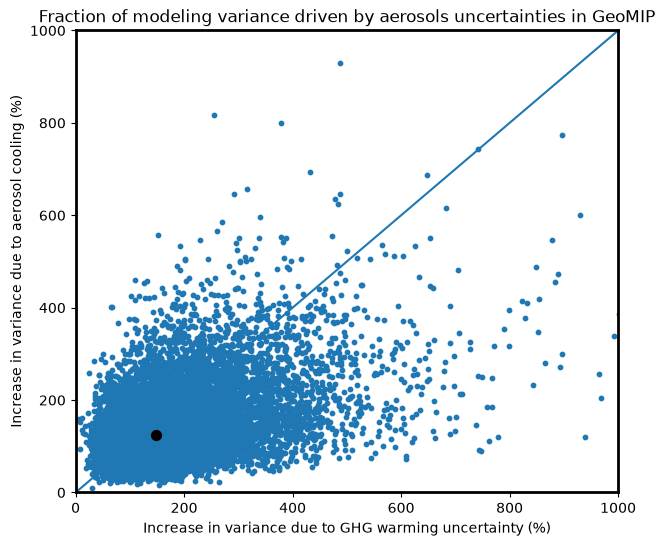

median ssp/sola %: 148.0331542029939
median sulf/sola %: 125.42727095456624


In [3]:
ssp_st = ssp5_delta_std1.reshape(-1, order="F")
sulf_st = sulf_delta_std1.reshape(-1, order="F")
sola_st = solar_delta_std1.reshape(-1, order="F")

mu.save_npz("2deg_pr", ssp_st=ssp_st, sulf_st=sulf_st, sola_st=sola_st,
            sulf_delta_std1=sulf_delta_std1)
print("saved data_py/2deg_pr.npz")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(np.abs(ssp_st) / sola_st * 100, np.abs(sulf_st) / sola_st * 100, s=10)
ax.scatter(np.nanmedian(np.abs(ssp_st) / sola_st * 100),
           np.nanmedian(np.abs(sulf_st) / sola_st * 100), s=50, c="k")
ax.plot([0, 1000], [0, 1000])
ax.set_xlim(0, 1000); ax.set_ylim(0, 1000)
ax.set_xlabel("Increase in variance due to GHG warming uncertainty (%)")
ax.set_ylabel("Increase in variance due to aerosol cooling (%)")
ax.set_title("Fraction of modeling variance driven by aerosols uncertainties in GeoMIP")
for s in ax.spines.values():
    s.set_linewidth(2)
plt.show()

print("median ssp/sola %:", np.nanmedian(np.abs(ssp_st) / sola_st * 100))
print("median sulf/sola %:", np.nanmedian(np.abs(sulf_st) / sola_st * 100))